# ModernTCN Training Results Visualization

Visualize convergence, confusion matrix, per-class metrics, and error analysis
for the best ModernTCN run on CAN-ML dataset.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append('../')
print(sys.path[-3:])

['', '/home/hieutt/miniconda3/envs/torchtf/lib/python3.9/site-packages', '../']


In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import torch
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# === CHANGE THIS to your run folder ===
# RUN_DIR = Path('../save/moderntcn/forester/mtcn_bs256_dim128_low_dr_lr0.001_s42')
RUN_DIR = Path('../save/ms_moderntcn/forester/ms_cat_3_5_7_9_13_mean_s42')

# Load history
history = json.loads((RUN_DIR / 'history.json').read_text())
print(f'Run folder: {RUN_DIR}')
print(f'Epochs trained: {len(history["train_loss"])}')
print(f'Keys: {list(history.keys())}')

Run folder: ../save/ms_moderntcn/forester/ms_cat_3_5_7_9_13_mean_s42
Epochs trained: 100
Keys: ['train_loss', 'val_loss', 'val_acc', 'val_f1', 'test_loss', 'test_acc', 'test_f1', 'lr']


## 1. Training Convergence

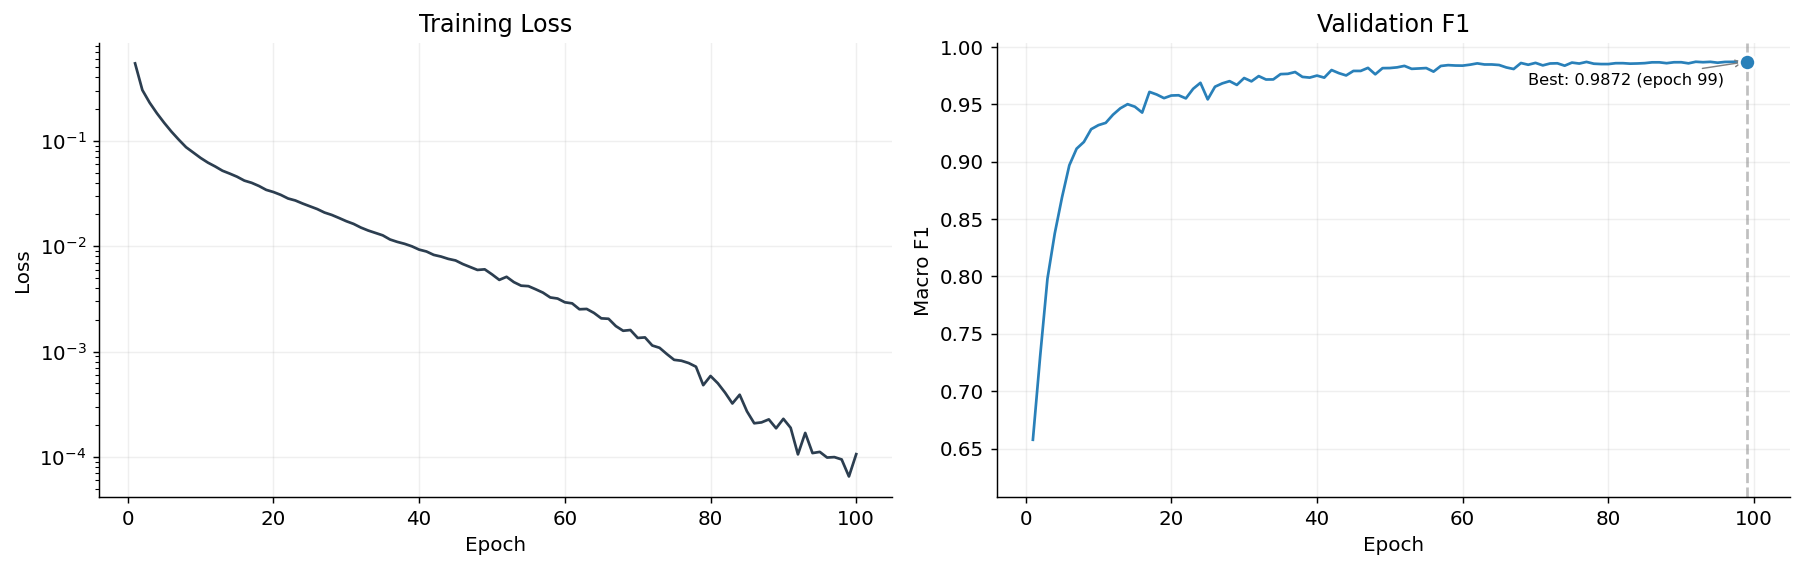

Best epoch: 99
Best val F1: 0.987235
Test F1 @ best val: 0.984656


In [3]:
epochs = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1) Training loss
ax = axes[0]
ax.plot(epochs, history['train_loss'], color='#2c3e50', linewidth=1.5)
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Training Loss')
ax.set_yscale('log')
ax.grid(alpha=0.2)

# 2) Val F1
ax = axes[1]
ax.plot(epochs, history['val_f1'], color='#2980b9', linewidth=1.5)
best_epoch = np.argmax(history['val_f1']) + 1
best_val = max(history['val_f1'])
ax.axvline(best_epoch, color='gray', linestyle='--', alpha=0.5)
ax.scatter([best_epoch], [best_val], color='#2980b9', s=80, zorder=5,
           edgecolors='white', linewidth=1.5)
ax.annotate(f'Best: {best_val:.4f} (epoch {best_epoch})',
            xy=(best_epoch, best_val), xytext=(best_epoch - 30, best_val - 0.02),
            fontsize=9, arrowprops=dict(arrowstyle='->', color='gray', lw=0.8))
ax.set_xlabel('Epoch')
ax.set_ylabel('Macro F1')
ax.set_title('Validation F1')
ax.set_ylim(bottom=max(0, min(history['val_f1']) - 0.05))
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(RUN_DIR / 'convergence.png', dpi=200, bbox_inches='tight')
plt.show()

print(f'Best epoch: {best_epoch}')
print(f'Best val F1: {best_val:.6f}')
print(f'Test F1 @ best val: {history["test_f1"][best_epoch - 1]:.6f}')

## 2. Load Best Checkpoint & Evaluate

In [4]:
# Load best checkpoint
ckpt = torch.load(RUN_DIR / 'best_val.pth', map_location='cpu', weights_only=False)

class_names = ckpt.get('class_names',
    ['normal', 'combined', 'dos', 'fuzzing', 'gear',
     'interval', 'rpm', 'speed', 'standstill', 'systematic'])
num_classes = len(class_names)
args = ckpt.get('args', {})

print(f'Checkpoint epoch: {ckpt["epoch"]}')
print(f'Classes: {class_names}')
print(f'Config: dims={args.get("dims")}, dropout={args.get("dropout")}, lr={args.get("lr")}')

Checkpoint epoch: 99
Classes: ['normal', 'combined', 'dos', 'fuzzing', 'gear', 'interval', 'rpm', 'speed', 'standstill', 'systematic']
Config: dims=[128, 256], dropout=0.1, lr=0.001


In [6]:
# Re-evaluate on test set to get predictions
import torch
from networks.moderntcn_can import ModernTCN_CAN
from torch.utils.data import DataLoader, TensorDataset

DATA_DIR = Path('../data/2017-subaru-forester/preprocessed')
test_data = torch.load(DATA_DIR / 'test.pt', weights_only=False)
X_test, y_test = test_data['X'].float(), test_data['y']

is_ivn = 'ens_k' in args   # checkpoint from train_ivn_tcn.py

if is_ivn:
    from networks.ivn_tcn import IVN_TCN
    model = IVN_TCN(
        seq_len=X_test.shape[1], nvars=X_test.shape[2], num_classes=num_classes,
        use_embedding=args.get('use_embedding', True), d_emb=args.get('d_emb', 8),
        n_freq=args.get('n_freq', 16), emb_sigma=args.get('emb_sigma', 1.0),
        cat_col=None if args.get('cat_col', 0) < 0 else args.get('cat_col', 0),
        patch_size=args.get('patch_size', 8), patch_stride=args.get('patch_stride', 4),
        dims=args.get('dims', [64, 128]), num_blocks=args.get('num_blocks', [1, 1]),
        large_sizes=args.get('large_sizes', [13, 13]), small_size=args.get('small_size', 5),
        ffn_ratio=args.get('ffn_ratio', 2), dropout=args.get('dropout', 0.1),
        multi_scale=args.get('multi_scale', True),
        ms_kernel_sizes=args.get('ms_kernel_sizes', [3, 5, 13]),
        ms_fusion=args.get('ms_fusion', 'channel'),
        ens_k=args.get('ens_k', 8), head_hidden=args.get('head_hidden', 64),
        head_dropout=args.get('head_dropout', 0.1),
    )
    # robust-scaler stats and arb_id vocab are buffers, restored by load_state_dict
else:
    # Old checkpoints: no 'multi_scale' key = vanilla run; multi-scale runs
    # trained before 'ms_fusion' existed used sum fusion.
    multi_scale = args.get('multi_scale', False)
    model = ModernTCN_CAN(
        seq_len=X_test.shape[1], nvars=X_test.shape[2], num_classes=num_classes,
        patch_size=args.get('patch_size', 8), patch_stride=args.get('patch_stride', 4),
        dims=args.get('dims', [128, 256]), num_blocks=args.get('num_blocks', [1, 1]),
        large_sizes=args.get('large_sizes', [13, 13]), small_size=args.get('small_size', 5),
        ffn_ratio=args.get('ffn_ratio', 2), dropout=args.get('dropout', 0.1),
        head_dropout=args.get('head_dropout', 0.0),
        class_dropout=args.get('class_dropout', 0.0),
        multi_scale=multi_scale,
        ms_kernel_sizes=args.get('ms_kernel_sizes', [3, 7, 13]),
        ms_fusion=args.get('ms_fusion', 'sum' if multi_scale else 'concat'),
        head_type=args.get('head_type', 'flatten'),
    )

model.load_state_dict(ckpt['model_state_dict'])   # strict: fails loudly on config mismatch
model.eval()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=4096, shuffle=False)

all_preds, all_targets = [], []
with torch.no_grad():
    for X, y in test_loader:
        out = model(X.to(device))
        if is_ivn:                       # (B, k, C): average member probabilities
            out = IVN_TCN.ensemble_proba(out)
        all_preds.append(out.argmax(-1).cpu())
        all_targets.append(y)

preds = torch.cat(all_preds).numpy()
targets = torch.cat(all_targets).numpy()

print(f'Model: {"IVN-TCN" if is_ivn else "ModernTCN"} | '
      f'multi_scale={args.get("multi_scale", False)} '
      f'kernels={args.get("ms_kernel_sizes")} fusion={args.get("ms_fusion")} '
      f'head={args.get("head_type", "ens" if is_ivn else "flatten")}')
print(f'Params: {sum(p.numel() for p in model.parameters()):,}')
print(f'Test samples: {len(targets)}')
print(f'Test F1 (macro): {f1_score(targets, preds, average="macro"):.6f}')

Model: ModernTCN | multi_scale=True kernels=[3, 5, 7, 9, 13] fusion=concat head=mean
Params: 9,519,242
Test samples: 174725
Test F1 (macro): 0.984656


## 3. Confusion Matrix

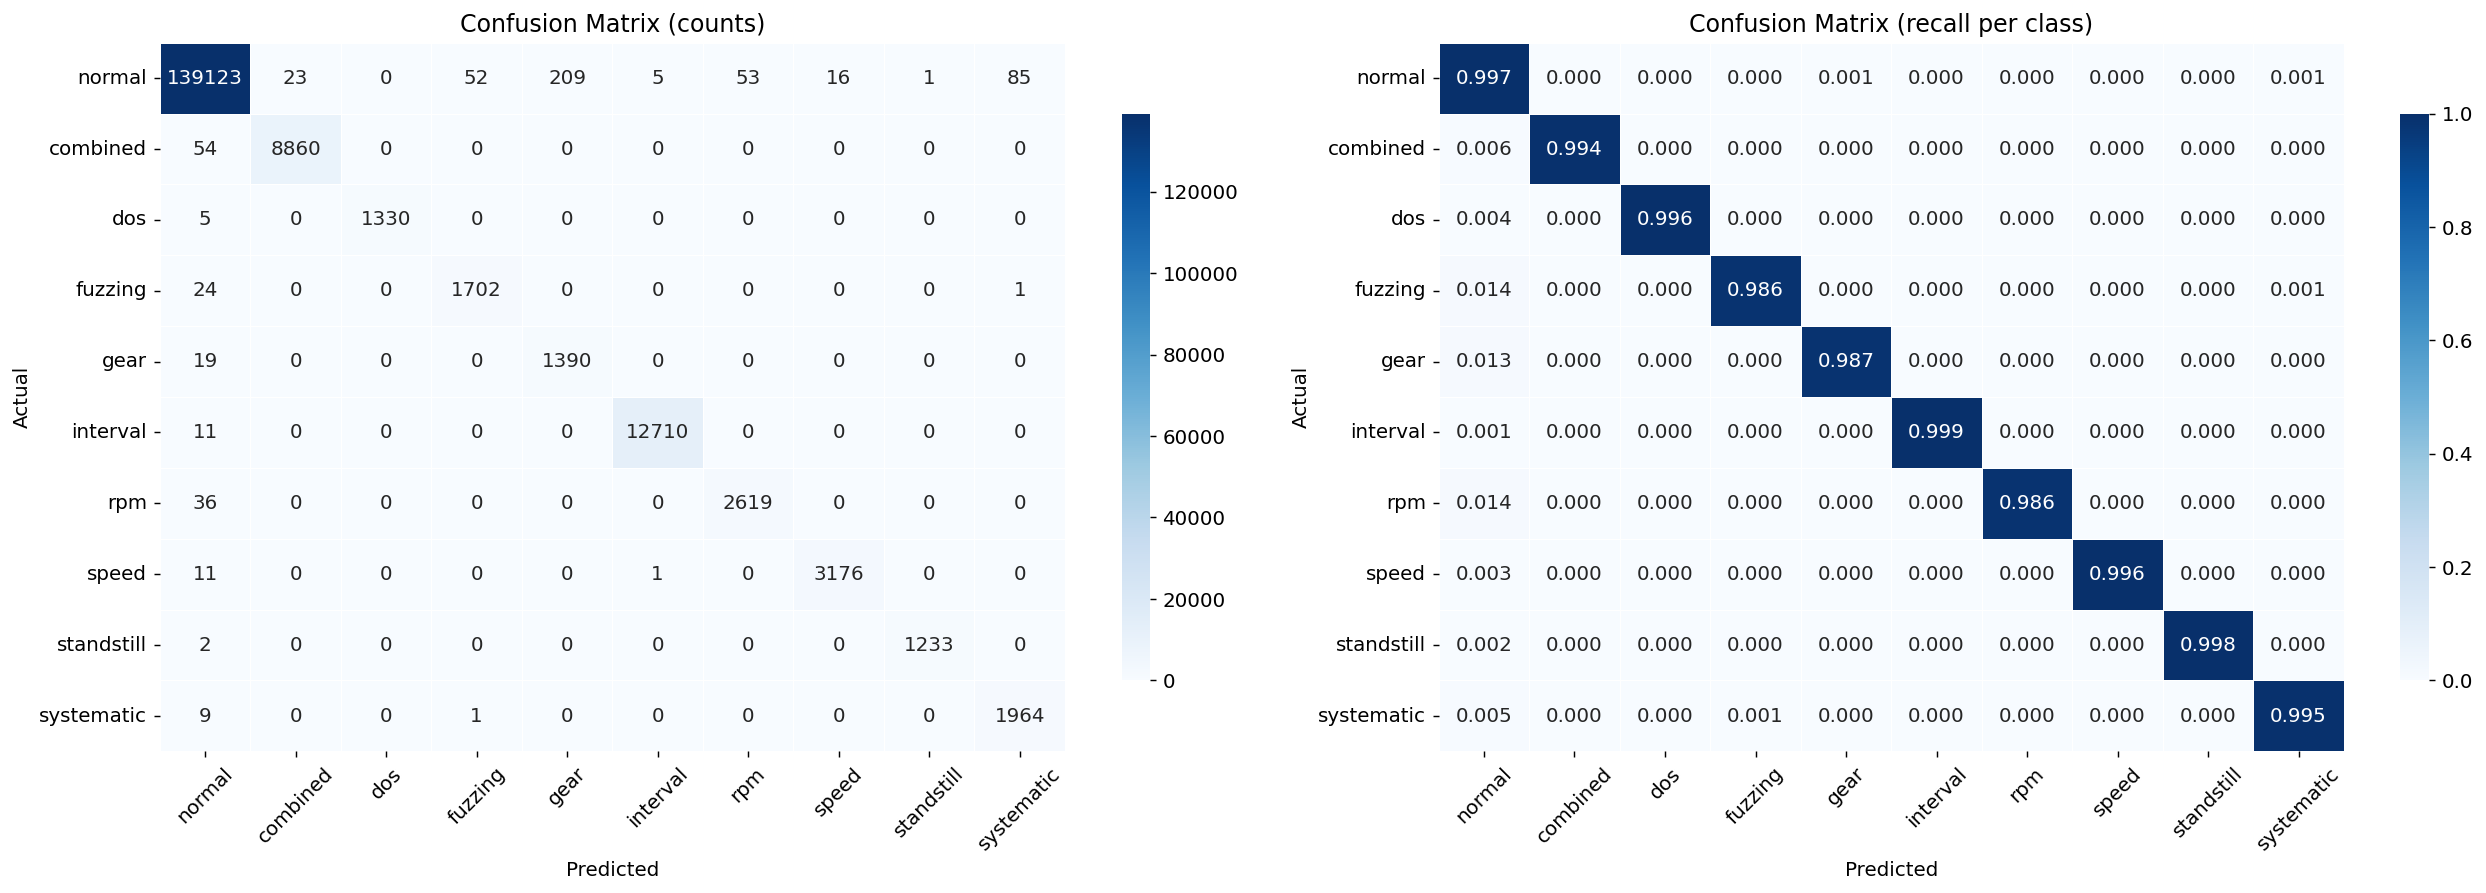

In [7]:
cm = confusion_matrix(targets, preds)

# Normalized confusion matrix (row-wise = recall per class)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

# Raw counts
ax = axes[0]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names,
            yticklabels=class_names, ax=ax, cbar_kws={'shrink': 0.8},
            linewidths=0.5, linecolor='white')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Confusion Matrix (counts)')
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)

# Normalized (recall)
ax = axes[1]
sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues', xticklabels=class_names,
            yticklabels=class_names, ax=ax, vmin=0, vmax=1,
            cbar_kws={'shrink': 0.8}, linewidths=0.5, linecolor='white')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Confusion Matrix (recall per class)')
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig(RUN_DIR / 'confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Per-class Metrics

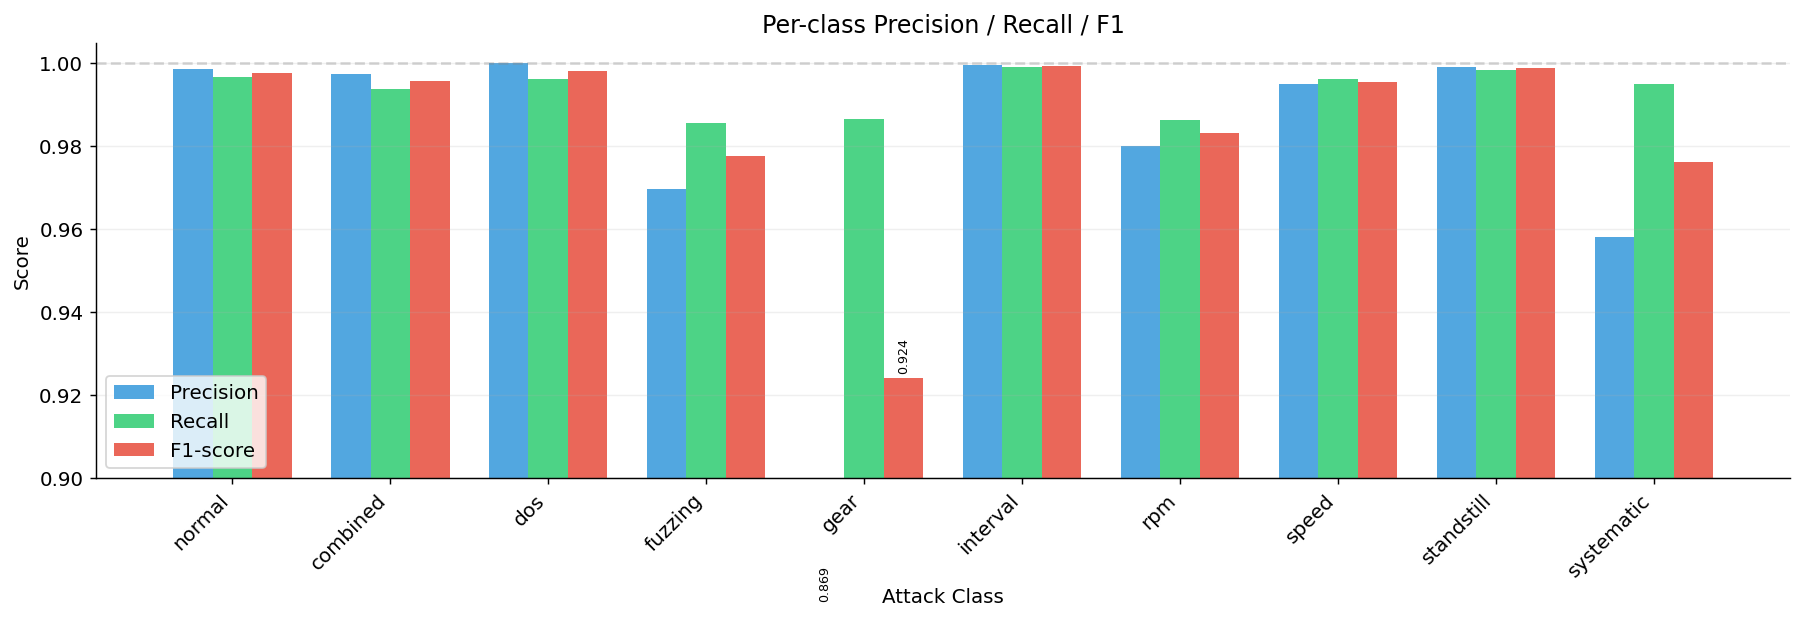

              precision    recall  f1-score   support

      normal     0.9988    0.9968    0.9978    139567
    combined     0.9974    0.9939    0.9957      8914
         dos     1.0000    0.9963    0.9981      1335
     fuzzing     0.9698    0.9855    0.9776      1727
        gear     0.8693    0.9865    0.9242      1409
    interval     0.9995    0.9991    0.9993     12721
         rpm     0.9802    0.9864    0.9833      2655
       speed     0.9950    0.9962    0.9956      3188
  standstill     0.9992    0.9984    0.9988      1235
  systematic     0.9580    0.9949    0.9761      1974

    accuracy                         0.9965    174725
   macro avg     0.9767    0.9934    0.9847    174725
weighted avg     0.9966    0.9965    0.9965    174725



In [8]:
# Classification report
report = classification_report(targets, preds, target_names=class_names,
                                digits=4, zero_division=0, output_dict=True)

# Extract per-class metrics
classes = class_names
precision = [report[c]['precision'] for c in classes]
recall = [report[c]['recall'] for c in classes]
f1 = [report[c]['f1-score'] for c in classes]
support = [report[c]['support'] for c in classes]

# Bar chart
x = np.arange(len(classes))
width = 0.25

fig, ax = plt.subplots(figsize=(14, 5))
bars1 = ax.bar(x - width, precision, width, label='Precision', color='#3498db', alpha=0.85)
bars2 = ax.bar(x, recall, width, label='Recall', color='#2ecc71', alpha=0.85)
bars3 = ax.bar(x + width, f1, width, label='F1-score', color='#e74c3c', alpha=0.85)

ax.set_xlabel('Attack Class')
ax.set_ylabel('Score')
ax.set_title('Per-class Precision / Recall / F1')
ax.set_xticks(x)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.set_ylim(0.9, 1.005)
ax.legend(loc='lower left')
ax.axhline(y=1.0, color='gray', linestyle='--', alpha=0.3)
ax.grid(axis='y', alpha=0.2)

# Add value labels on bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        if h < 0.95:
            ax.text(bar.get_x() + bar.get_width()/2, h + 0.001,
                    f'{h:.3f}', ha='center', va='bottom', fontsize=7, rotation=90)

plt.tight_layout()
plt.savefig(RUN_DIR / 'per_class_metrics.png', dpi=200, bbox_inches='tight')
plt.show()

# Print report
print(classification_report(targets, preds, target_names=class_names, digits=4, zero_division=0))

## 5. Class Distribution & Error Analysis

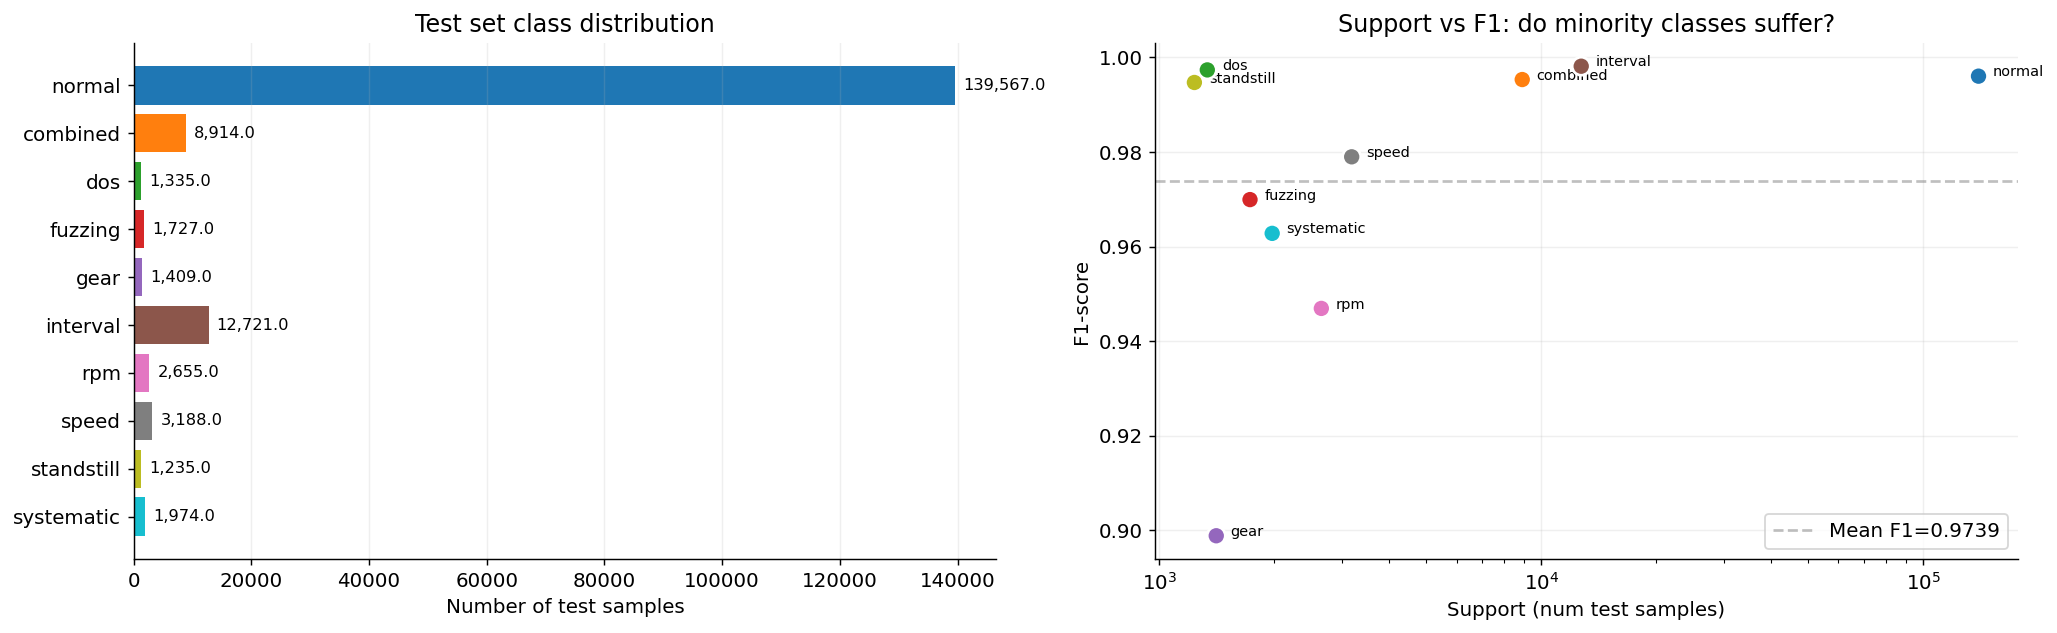

In [17]:
# Support vs F1 scatter: see if minority classes have lower F1
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 5a) Support distribution
ax = axes[0]
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))
bars = ax.barh(classes, support, color=colors)
ax.set_xlabel('Number of test samples')
ax.set_title('Test set class distribution')
for bar, s in zip(bars, support):
    ax.text(bar.get_width() + max(support)*0.01, bar.get_y() + bar.get_height()/2,
            f'{s:,}', va='center', fontsize=9)
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.2)

# 5b) Support vs F1
ax = axes[1]
ax.scatter(support, f1, s=100, c=colors, edgecolors='white', linewidth=1.5, zorder=5)
for i, cls in enumerate(classes):
    ax.annotate(cls, (support[i], f1[i]), textcoords='offset points',
                xytext=(8, 0), fontsize=8, ha='left')
ax.set_xlabel('Support (num test samples)')
ax.set_ylabel('F1-score')
ax.set_title('Support vs F1: do minority classes suffer?')
ax.set_xscale('log')
ax.axhline(y=np.mean(f1), color='gray', linestyle='--', alpha=0.5, label=f'Mean F1={np.mean(f1):.4f}')
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(RUN_DIR / 'error_analysis.png', dpi=200, bbox_inches='tight')
plt.show()

In [18]:
# Where does the model make mistakes?
# Show top confusion pairs
np.fill_diagonal(cm, 0)  # zero out diagonal to see only errors
errors = []
for i in range(num_classes):
    for j in range(num_classes):
        if cm[i, j] > 0:
            errors.append((class_names[i], class_names[j], cm[i, j]))

errors.sort(key=lambda x: x[2], reverse=True)

print('Top 15 confusion pairs (actual -> predicted : count)')
print('=' * 55)
for actual, predicted, count in errors[:15]:
    print(f'  {actual:>12s} -> {predicted:<12s} : {count:,}')

Top 15 confusion pairs (actual -> predicted : count)
        normal -> gear         : 251
           rpm -> normal       : 175
        normal -> systematic   : 128
        normal -> rpm          : 103
        normal -> speed        : 67
         speed -> normal       : 61
      combined -> normal       : 60
        normal -> fuzzing      : 54
          gear -> normal       : 54
       fuzzing -> normal       : 46
        normal -> interval     : 30
        normal -> combined     : 20
    systematic -> normal       : 19
      interval -> normal       : 14
    standstill -> normal       : 12


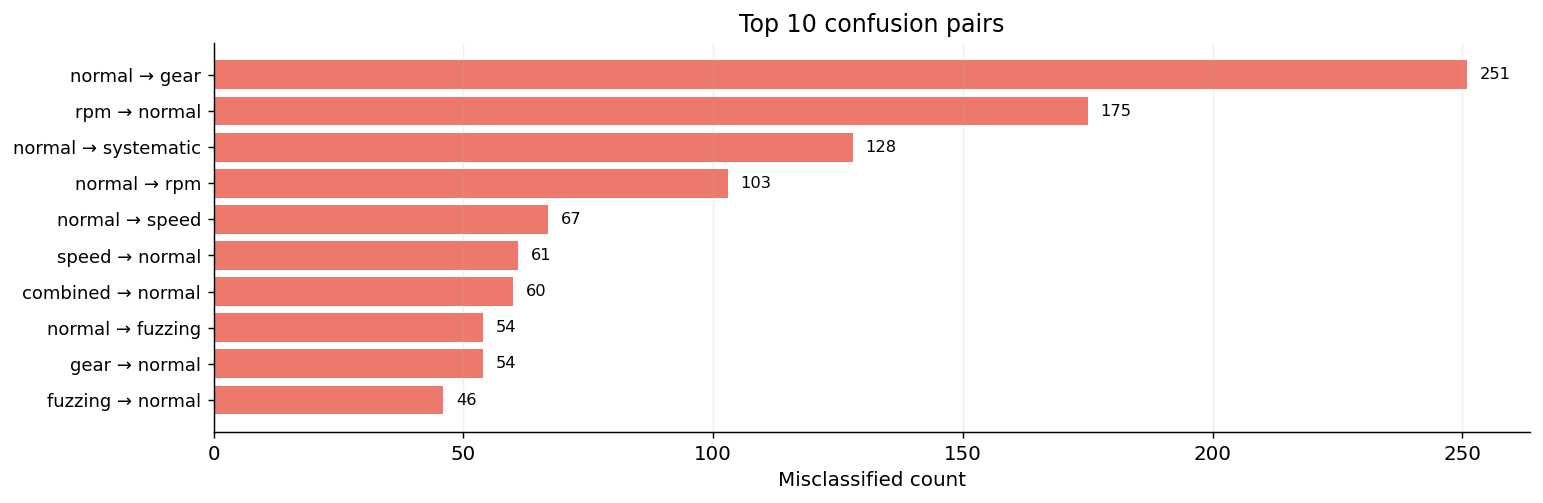

In [19]:
# Visualize top confusion pairs as horizontal bar chart
top_n = 10
top_errors = errors[:top_n]
labels = [f'{a} → {p}' for a, p, _ in top_errors]
counts = [c for _, _, c in top_errors]

fig, ax = plt.subplots(figsize=(12, 4))
y_pos = range(len(labels))
ax.barh(y_pos, counts, color='#e74c3c', alpha=0.75)
ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=10)
ax.set_xlabel('Misclassified count')
ax.set_title('Top 10 confusion pairs')
ax.invert_yaxis()
for i, c in enumerate(counts):
    ax.text(c + max(counts)*0.01, i, f'{c:,}', va='center', fontsize=9)
ax.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.savefig(RUN_DIR / 'top_confusions.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Summary

In [20]:
# Reload original CM (before zeroing diagonal)
cm_full = confusion_matrix(targets, preds)
total_correct = np.trace(cm_full)
total_samples = cm_full.sum()

print('=' * 60)
print('  MODERNTCN CAN-ML RESULTS SUMMARY')
print('=' * 60)
print(f'  Model        : ModernTCN dims={args.get("dims")}')
print(f'  Parameters   : {sum(p.numel() for p in model.parameters()):,}')
print(f'  Dataset      : CAN-ML 2017-subaru-forester')
print(f'  Classes      : {num_classes}')
print(f'  Test samples : {total_samples:,}')
print(f'  Accuracy     : {total_correct/total_samples:.6f} ({total_correct:,}/{total_samples:,})')
print(f'  Macro F1     : {f1_score(targets, preds, average="macro"):.6f}')
print(f'  Weighted F1  : {f1_score(targets, preds, average="weighted"):.6f}')
print(f'  Best epoch   : {best_epoch}')
print(f'  Training time: ~{len(history["train_loss"]):,} epochs')
print()
print('  Per-class F1:')
for cls, f in zip(class_names, f1):
    bar = '█' * int(f * 30)
    print(f'    {cls:>12s} : {f:.4f} {bar}')
print()
print(f'  Worst class  : {class_names[np.argmin(f1)]} (F1={min(f1):.4f})')
print(f'  Best class   : {class_names[np.argmax(f1)]} (F1={max(f1):.4f})')

  MODERNTCN CAN-ML RESULTS SUMMARY
  Model        : ModernTCN dims=[128, 256]
  Parameters   : 4,596,362
  Dataset      : CAN-ML 2017-subaru-forester
  Classes      : 10
  Test samples : 174,725
  Accuracy     : 0.993636 (173,613/174,725)
  Macro F1     : 0.973912
  Weighted F1  : 0.993691
  Best epoch   : 93
  Training time: ~100 epochs

  Per-class F1:
          normal : 0.9960 █████████████████████████████
        combined : 0.9953 █████████████████████████████
             dos : 0.9974 █████████████████████████████
         fuzzing : 0.9699 █████████████████████████████
            gear : 0.8988 ██████████████████████████
        interval : 0.9982 █████████████████████████████
             rpm : 0.9469 ████████████████████████████
           speed : 0.9790 █████████████████████████████
      standstill : 0.9947 █████████████████████████████
      systematic : 0.9628 ████████████████████████████

  Worst class  : gear (F1=0.8988)
  Best class   : interval (F1=0.9982)
